# Imports

In [405]:
import numpy as np
import matplotlib.pyplot as plt
import json
from numba import njit
from scipy.signal import envelope

# Import parameters

In [406]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    total_depth_sample = (total_depth / 2) / samples #total depth in m / number of samples = depth per sample
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples 
    params["simulation"]["total_depth_sample"] = total_depth_sample #depth per sample in m
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])
    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Total depth samples: ", total_depth_sample)
    print("Step size: ", step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [407]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  3200
Total depth samples:  3.125e-06
Step size:  4.166666666666667e-09 s
Maximal acquisition depth: 0.01 m
Lateral step:  2.5e-05 m


## Objects

In [408]:
class Objects:
    def __init__(self, depth, position):
        self.depth = depth
        self.position = position
        self.delays = np.zeros(params["array"]["length"])
        self.rf_matrix = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_zm = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_dc1 = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_dc2 = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.rf_matrix_rectangle = np.zeros((params["simulation"]["samples"], params["array"]["length"]))
        self.effective_array_length = 0
        self.transducers_in_effective_array = 0
        self.first_transducer = None


In [ ]:
objects = []

for reflector in params["objects"]:
    objects.append(Objects(reflector["depth"], reflector["position"]))

In [410]:
def find_object_effective_aperture(objects : Objects, aperture, pitch):
    for i in range(0, len(objects)):
        objects[i].effective_array_length =  objects[i].depth / aperture
        print(f"Object {i+1} effective array length: {objects[i].effective_array_length} m") 
        for j in range(0, params["array"]["length"]):
            if j*pitch >= objects[i].position - objects[i].effective_array_length / 2 and j*pitch <= objects[i].position + objects[i].effective_array_length / 2:
                if objects[i].first_transducer == None:
                    objects[i].first_transducer = j
                objects[i].transducers_in_effective_array += 1
        print(f"Object {i+1} transducers in effective array: {objects[i].transducers_in_effective_array}")   
        print(f"Object {i+1} first transducer: {objects[i].first_transducer}\n")             
        

find_object_effective_aperture(objects, params["array"]["aperture"], params["array"]["pitch"])

Object 1 effective array length: 0.00375 m
Object 1 transducers in effective array: 37
Object 1 first transducer: 52

Object 2 effective array length: 0.005 m
Object 2 transducers in effective array: 51
Object 2 first transducer: 55

Object 3 effective array length: 0.0038749999999999995 m
Object 3 transducers in effective array: 39
Object 3 first transducer: 56

Object 4 effective array length: 0.011249999999999998 m
Object 4 transducers in effective array: 107
Object 4 first transducer: 0



# NSI

## Import delays

In [411]:
def import_delay_data(objects, file="./data/csv/delays/delay_matrix_object"):
    for i in range(len(objects)):
        objects[i].delays = np.genfromtxt(f"{file}{i+1}.csv", delimiter=",")


In [412]:
import_delay_data(objects)

### Display delays

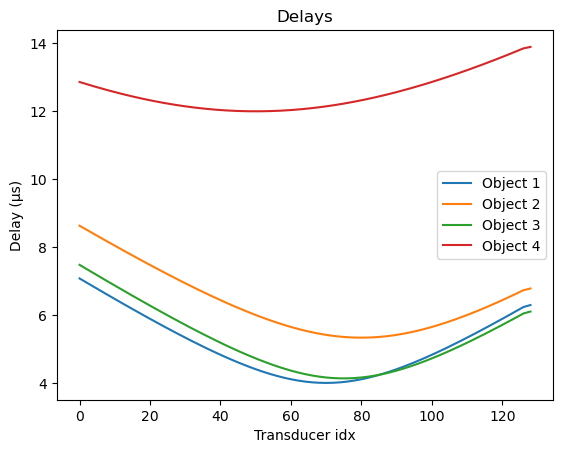

In [413]:
plt.figure()    
for i in range(0, len(objects)):
    plt.plot(pos, objects[i].delays*1e6, label = f"Object {i+1}")
plt.title("Delays")
plt.xlabel("Transducer idx")
plt.ylabel("Delay (µs)")
plt.legend()
plt.show()

## Import RF matrices

In [414]:
def import_RF_data(objects, file="./data/csv/rf_data/rf_matrix_object"):
    for i in range(len(objects)):
        objects[i].rf_matrix = np.genfromtxt(f"{file}{i+1}.csv", delimiter=',').reshape(params["simulation"]["samples"], params["array"]["length"])
        objects[i].rf_matrix_zm = objects[i].rf_matrix.copy()
        objects[i].rf_matrix_dc1 = objects[i].rf_matrix.copy()
        objects[i].rf_matrix_dc2 = objects[i].rf_matrix.copy()
        objects[i].rf_matrix_rectangle = objects[i].rf_matrix.copy()

In [415]:
import_RF_data(objects)

### Display RF data

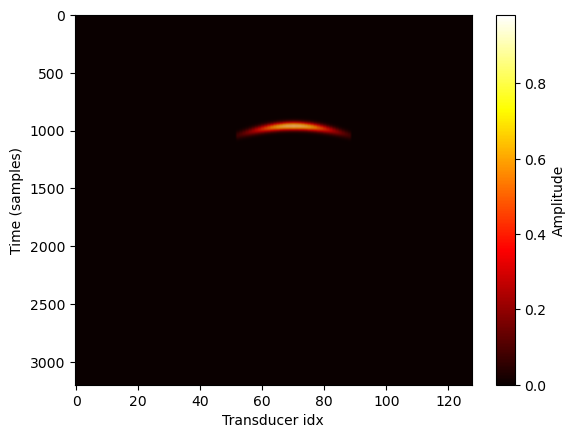

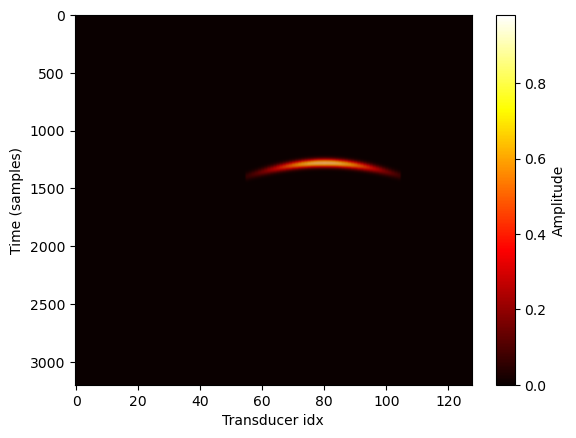

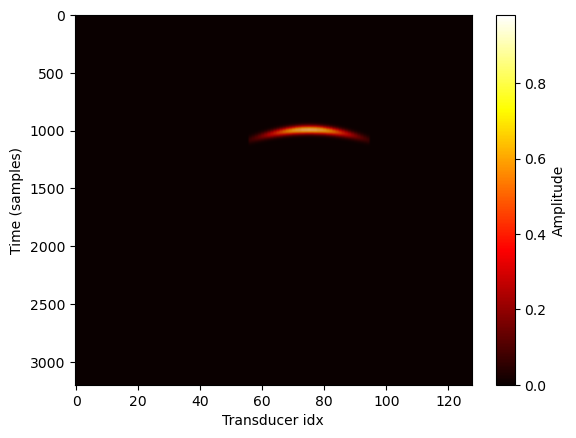

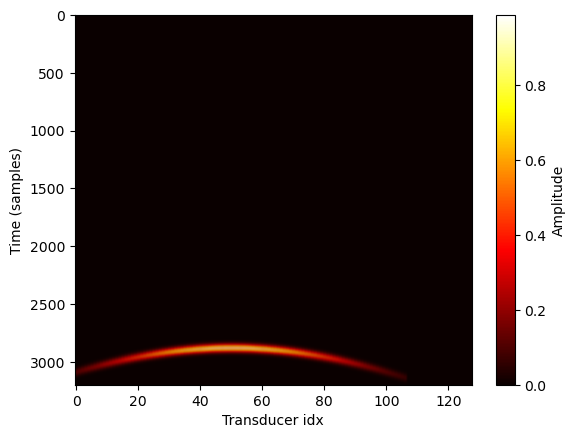

In [416]:
for i in range(0, len(objects)):
    objects[i].rf_matrix.tofile(f"./data/csv/rf_matrix_object{i+1}.csv", sep=",")
    plt.figure()
    plt.imshow(abs(objects[i].rf_matrix), cmap='hot', aspect='auto')
    plt.xlabel("Transducer idx")
    plt.ylabel("Time (samples)")
    plt.savefig(f"./data/images/rf_matrix_object{i+1}.png")
    plt.colorbar(label="Amplitude")
    plt.show()

## Apodization function

In [417]:
def generate_zm_apodization(cur_object : Objects, transducer_idx, offset=0, mirror=False):
    if transducer_idx - cur_object.first_transducer >= 0: #making sure we are in the effective array range
        transducer_relative_idx = transducer_idx - cur_object.first_transducer
        if transducer_relative_idx >= 0 and transducer_relative_idx < cur_object.transducers_in_effective_array / 2:
            if mirror:
                return -1 + offset
            else:
                return 1 + offset
        elif transducer_relative_idx>=cur_object.transducers_in_effective_array/2 and transducer_relative_idx < cur_object.transducers_in_effective_array:
            if mirror:
                return 1 + offset
            else:
                return -1 + offset
    return 0 + offset
        
def generate_rectangle_apodization(amount_kept,  index, pitch, cur_object : Objects, offset=0):
    half_array = cur_object.effective_array_length/2
    amount_kept = (1 - amount_kept) * half_array
    if index * pitch >= cur_object.position - half_array + amount_kept and index * pitch <= cur_object.position + half_array - amount_kept:
        return 1 + offset
    else :
        return 0 + offset

In [418]:
pos

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 128])

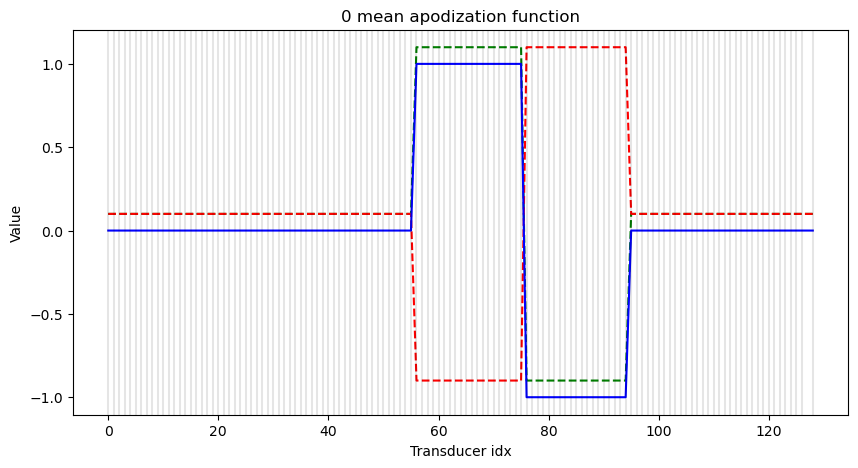

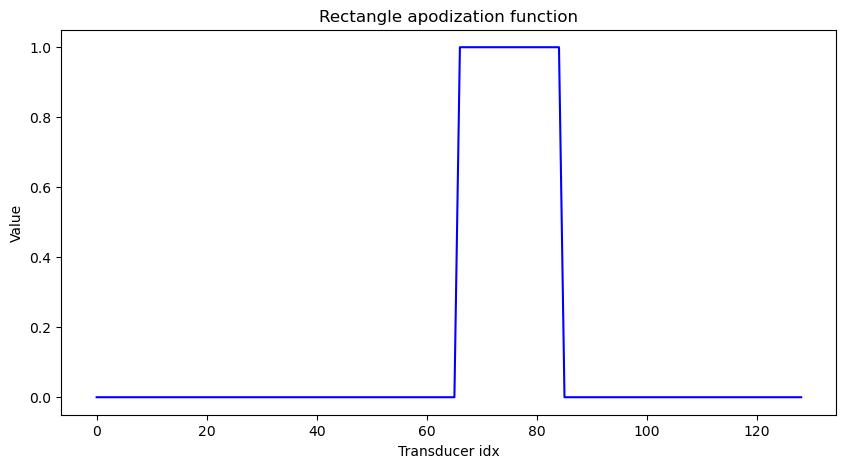

In [419]:
test_obj = objects[2]
apodization_zm = np.array([generate_zm_apodization(test_obj, i, offset=0, mirror=False) for i in range(params["array"]["length"])])
apodization_dc1 = np.array([generate_zm_apodization(test_obj, i, offset=0.1, mirror=False) for i in range(params["array"]["length"])])
apodization_dc2 = np.array([generate_zm_apodization(test_obj, i, offset=0.1, mirror=True) for i in range(params["array"]["length"])])
apodization_rectangle = np.array([generate_rectangle_apodization(0.5, i, params["array"]["pitch"], test_obj, offset=0) for i in range(params["array"]["length"])])


plt.figure(figsize=(10, 5))
plt.plot(pos, apodization_dc1, color='g', ls='--')
plt.plot(pos, apodization_dc2, color='r', ls='--')
plt.plot(pos, apodization_zm, color='b')
for x in pos:
    plt.axvline(x=x, color='black', ls='-', alpha=0.1)
plt.title('0 mean apodization function')
plt.xlabel('Transducer idx')

plt.ylabel('Value')
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(pos, apodization_rectangle, color='b')
plt.title('Rectangle apodization function')
plt.xlabel('Transducer idx')
plt.ylabel('Value')
plt.show()

## Applying apodization

In [420]:
def is_in_transducer_range(current_object : Objects, current_transducer, pitch):
    if current_transducer * pitch <= current_object.position - current_object.effective_array_length / 2 or current_transducer * pitch >= current_object.position + current_object.effective_array_length / 2:
        return 0
    else:
        return 1

In [421]:
def get_rf_matrices(objects, array_length, pitch, samples):
    rf_matrix_zm_summed = np.zeros((samples, array_length))
    rf_matrix_dc1_summed = np.zeros((samples, array_length))
    rf_matrix_dc2_summed = np.zeros((samples, array_length))
    rf_matrix_rectangle_summed = np.zeros((samples, array_length))

    for i in range(0, len(objects)):
        apodization_rectangle = np.array([generate_rectangle_apodization(0.5, j, params["array"]["pitch"], objects[i], offset=0) for j in range(params["array"]["length"])])
        apodization_zm = np.array([generate_zm_apodization(objects[i], j, offset=0, mirror=False) for j in range(array_length)])
        apodization_dc1 = np.array([generate_zm_apodization(objects[i], j, offset=0.1, mirror=False) for j in range(array_length)])
        apodization_dc2 = np.array([generate_zm_apodization(objects[i], j, offset=0.1, mirror=True) for j in range(array_length)])
        
        for j in range(array_length):
            #for each transducer, generate the wave with the corresponding delay
            objects[i].rf_matrix_zm[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_zm[j]
            objects[i].rf_matrix_dc1[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_dc1[j]
            objects[i].rf_matrix_dc2[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_dc2[j]
            objects[i].rf_matrix_rectangle[:, j] *= is_in_transducer_range(objects[i], j, pitch) * apodization_rectangle[j]
        rf_matrix_zm_summed += objects[i].rf_matrix_zm
        rf_matrix_dc1_summed += objects[i].rf_matrix_dc1
        rf_matrix_dc2_summed += objects[i].rf_matrix_dc2
        rf_matrix_rectangle_summed += objects[i].rf_matrix_rectangle
    return rf_matrix_zm_summed, rf_matrix_dc1_summed, rf_matrix_dc2_summed, rf_matrix_rectangle_summed

In [422]:
rf_matrix_zm_summed, rf_matrix_dc1_summed, rf_matrix_dc2_summed, rf_matrix_rectangle_summed = get_rf_matrices(objects, params["array"]["length"], params["array"]["pitch"], params["simulation"]["samples"])

## Visualize summed RF matrices 

### ZM

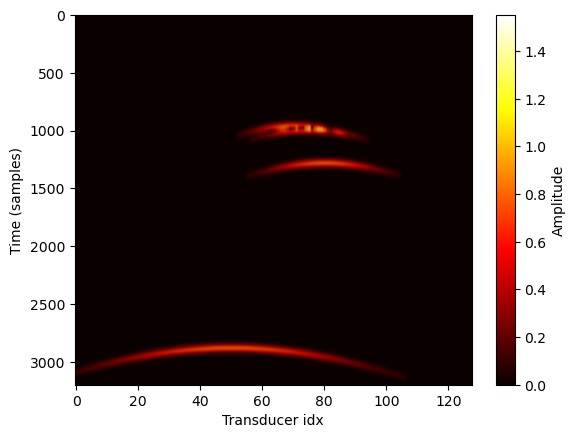

In [423]:
plt.imshow(abs(rf_matrix_zm_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

### DC1

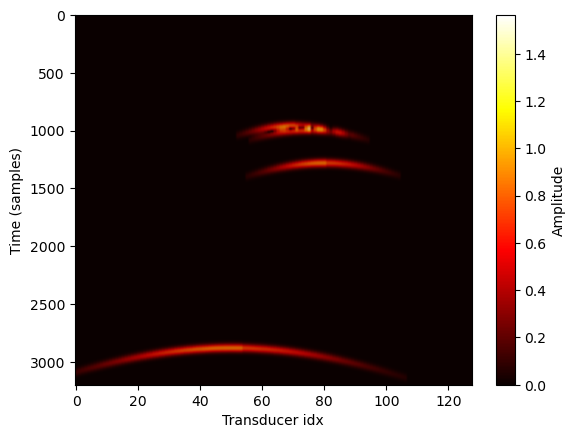

In [424]:
plt.imshow(abs(rf_matrix_dc1_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

### DC2

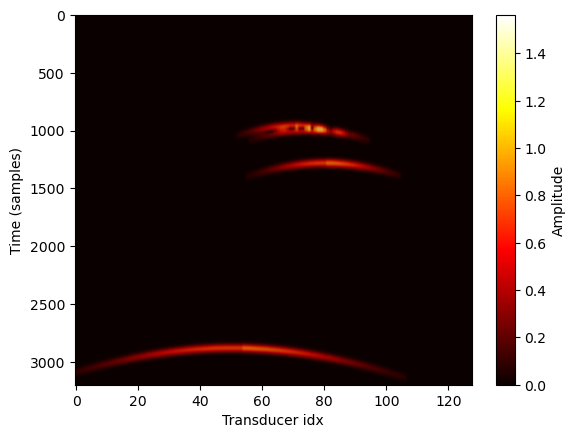

In [425]:
plt.imshow(abs(rf_matrix_dc2_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

### Rectangle

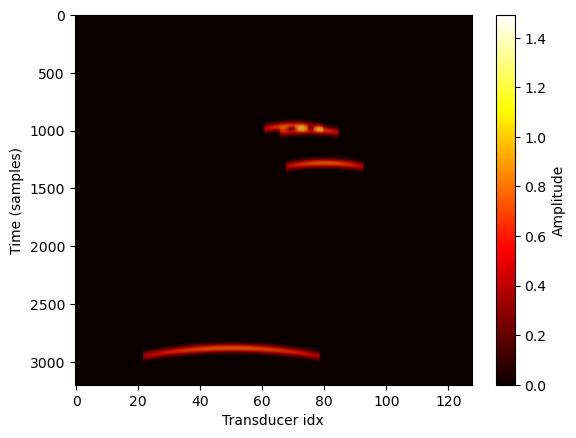

In [426]:
plt.imshow(abs(rf_matrix_rectangle_summed), cmap='hot', aspect='auto')
plt.xlabel("Transducer idx")
plt.ylabel("Time (samples)")
plt.colorbar(label="Amplitude")
plt.show()

## Beamforming

In [427]:
@njit(parallel=True)
def beamforming_opt(rf_matrix_summed, lateral_resolution, samples, total_depth_sample, pitch, c, array_length, sampling_rate):
    bf_matrix = np.zeros((samples, lateral_resolution))

    for j in range(0, lateral_resolution):

        for k in range(0, samples):

            depth = total_depth_sample*k
            position = (pitch * array_length) * (j / lateral_resolution) #pitch isnt the same as the distance between transducers
            # we normalize the index to the total array length

            for l in range(0, array_length):

                delay = (depth / c) + np.sqrt(depth**2 + (l * pitch - position)**2) / c
                delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)

                if delay_idx < samples:
                    bf_matrix[k,j] += rf_matrix_summed[delay_idx, l] #we take sample in calculated rf_matrix (faster than recalculating)
    print("Beamforming done")
    return bf_matrix

def save_beamformed_data(bf_matrix, filename, destination="./data_nsi/csv/beamformed/"):
    bf_matrix.tofile(f"{destination}{filename}.csv", sep=",")
    print("Beamformed data saved")

In [428]:
bf_matrix_zm = beamforming_opt(rf_matrix_zm_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])
save_beamformed_data(bf_matrix_zm, "bf_matrix_zm")

Beamforming done
Beamformed data saved


In [429]:
bf_matrix_dc1 = beamforming_opt(rf_matrix_dc1_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])
save_beamformed_data(bf_matrix_dc1, "bf_matrix_dc1")

Beamforming done
Beamformed data saved


In [430]:
bf_matrix_dc2 = beamforming_opt(rf_matrix_dc2_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])
save_beamformed_data(bf_matrix_dc2, "bf_matrix_dc2")

Beamforming done
Beamformed data saved


In [431]:
bm_matrix_nsi = (bf_matrix_dc1 + bf_matrix_dc2) / 2 - bf_matrix_zm
save_beamformed_data(bm_matrix_nsi, "bf_matrix_nsi")

Beamformed data saved


In [432]:
bf_matrix_rectangle = beamforming_opt(rf_matrix_rectangle_summed, params["simulation"]["lateral_resolution"], params["simulation"]["samples"], params["simulation"]["total_depth_sample"], params["array"]["pitch"], params["wave"]["c"], params["array"]["length"], params["wave"]["sampling_rate"])
save_beamformed_data(bf_matrix_rectangle, "bf_matrix_rectangle")

Beamforming done
Beamformed data saved


## Display beamformed image

### ZM

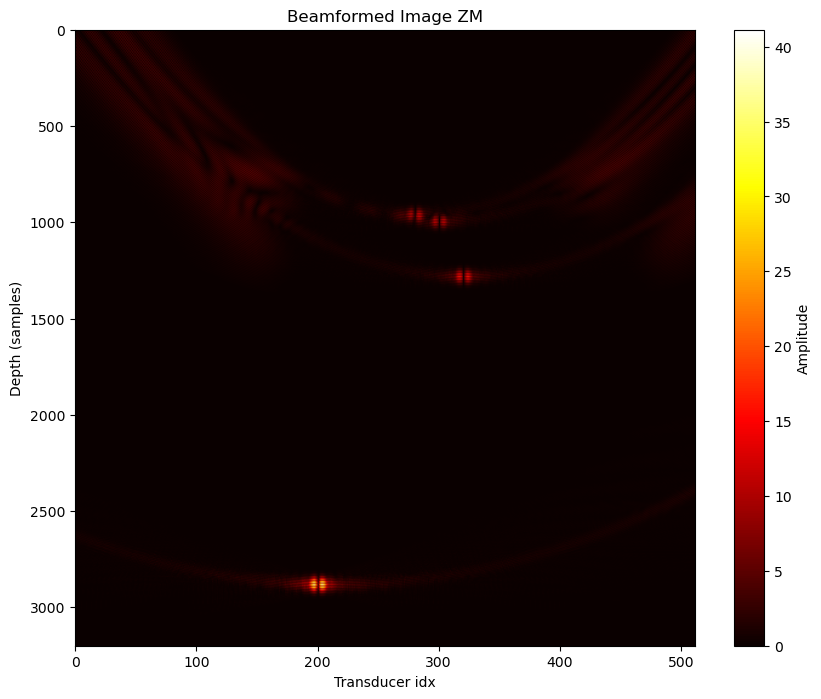

In [433]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_zm), cmap='hot', aspect='auto')
plt.title("Beamformed Image ZM")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_zm.png")
plt.show()

### DC1

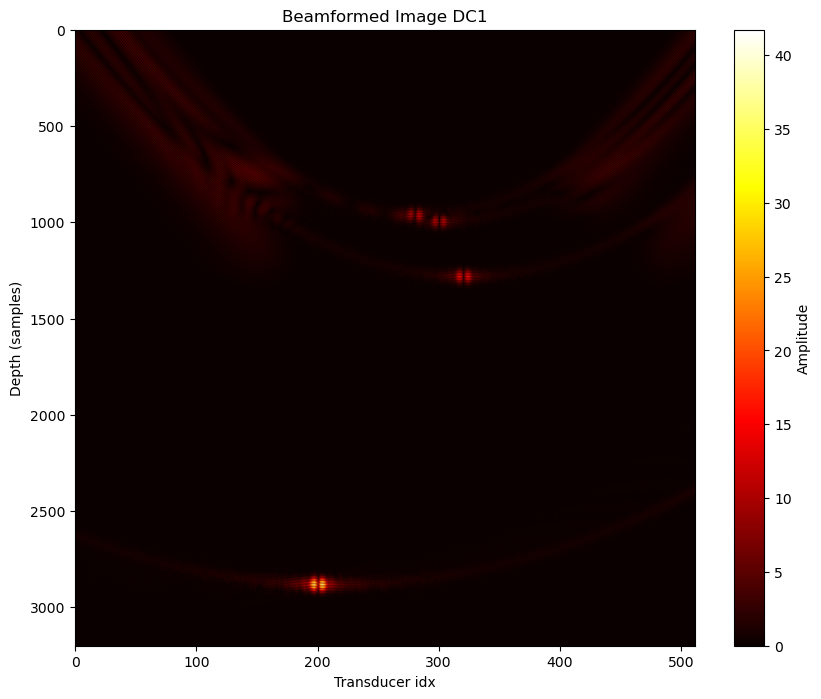

In [434]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_dc1), cmap='hot', aspect='auto')
plt.title("Beamformed Image DC1")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_dc1.png")
plt.show()

### DC2

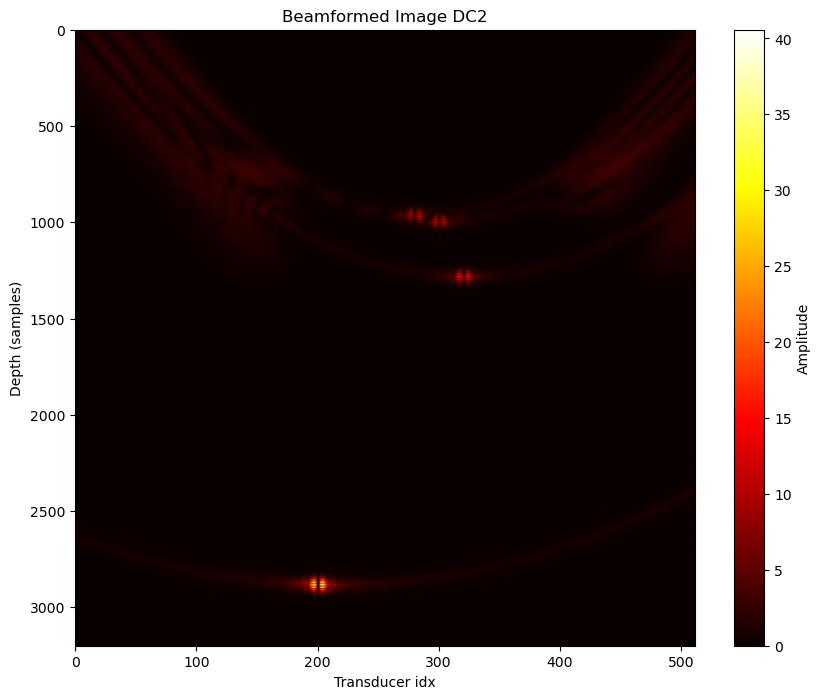

In [435]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_dc2), cmap='hot', aspect='auto')
plt.title("Beamformed Image DC2")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_dc2.png")
plt.show()

### NSI

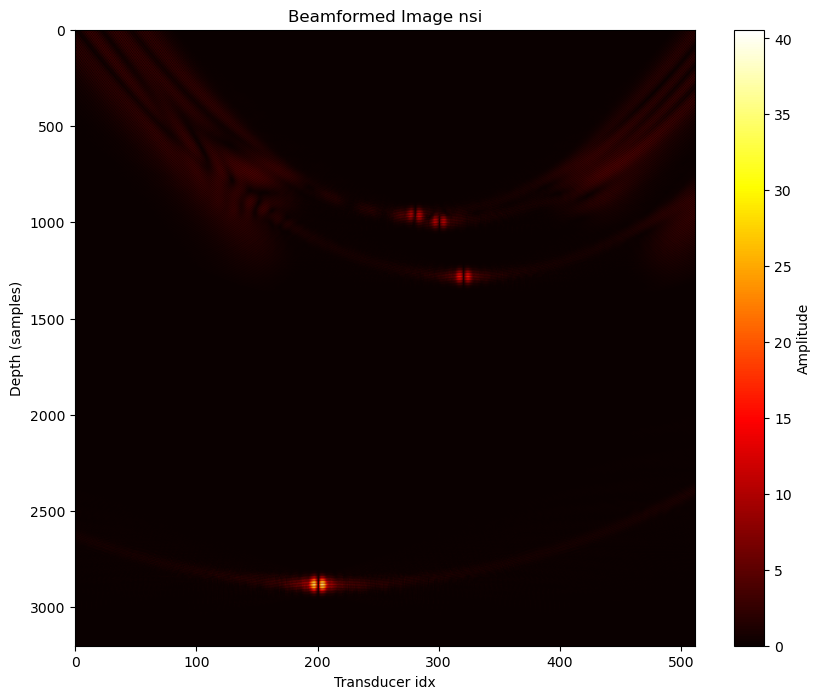

In [436]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bm_matrix_nsi), cmap='hot', aspect='auto')
plt.title("Beamformed Image nsi")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_matrix_nsi.png")
plt.show()

### Rectangle

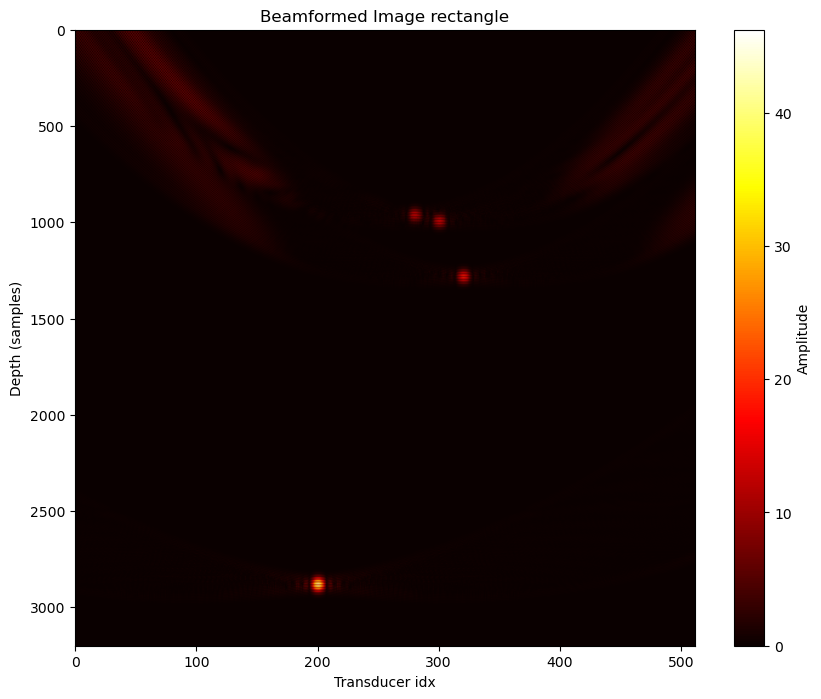

In [437]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix_rectangle), cmap='hot', aspect='auto')
plt.title("Beamformed Image rectangle")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data_nsi/images/bf_image_rectangle.png")
plt.show()

## Envelopes

In [441]:
env_zm = np.zeros((params["simulation"]["samples"], params["simulation"]["lateral_resolution"]))
env_dc1 = np.zeros((params["simulation"]["samples"], params["simulation"]["lateral_resolution"]))
env_dc2 = np.zeros((params["simulation"]["samples"], params["simulation"]["lateral_resolution"]))

for i in range(0, params["simulation"]["lateral_resolution"]):
    env_zm[:, i] = envelope(bf_matrix_zm[:, i], residual=None)
    env_dc1[:, i] = envelope(bf_matrix_dc1[:, i], residual=None)
    env_dc2[:, i] = envelope(bf_matrix_dc2[:, i], residual=None)


## Average offsets

In [442]:
env_nsi = (env_dc1 + env_dc2) / 2 - env_zm
env_nsi.tofile(f"./data_nsi/csv/beamformed/env_nsi.csv", sep=",")

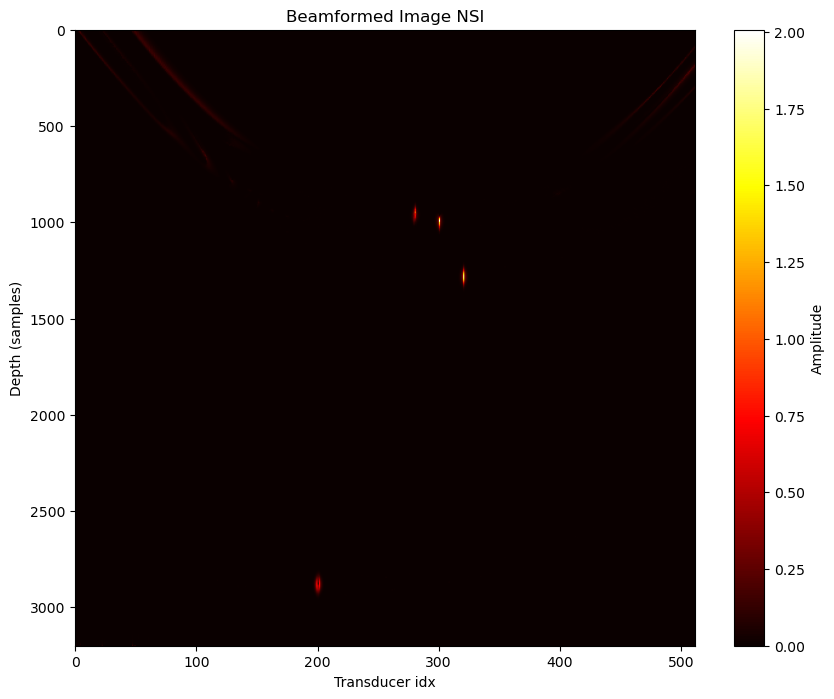

In [443]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(env_nsi), cmap='hot', aspect='auto')
plt.title("Beamformed Image NSI")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.show()